<a href="https://colab.research.google.com/github/caroline-reges/Image-Identification-Using-Deep-Learning/blob/main/Deep%20Learning%20Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import packages

In [1]:
#keeps google colab connected to my drive
from google.colab import drive
drive.mount('/content/drive')

import os #use to navigate folders

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files #used for saving files
from PIL import Image #used to look at image dimensions


Mounted at /content/drive


# Load Data

In [2]:
images_path = "/content/drive/MyDrive/animals10/raw-img"

print(os.listdir(images_path))

['horse', 'sheep', 'dog', 'elephant', 'butterfly', 'chicken', 'cat', 'cow', 'spider', 'squirrel']


# Data cleaning and EDA, Data Preprocessing

Change my folder names from italian to english

In [ ]:
translate = {"cane": "dog", "cavallo": "horse", "elefante": "elephant", "farfalla": "butterfly",
             "gallina": "chicken", "gatto": "cat", "mucca": "cow", "pecora": "sheep",
             "ragno": "spider", "scoiattolo": "squirrel"}
for italian, english in translate.items():
    old_path = os.path.join(images_path, italian) #create old folder path
    new_path = os.path.join(images_path, english) #create new folder path

    if os.path.exists(old_path): #I can run this code again and it won't give me errors
        os.rename(old_path, new_path) #rename folder


Check class distribution

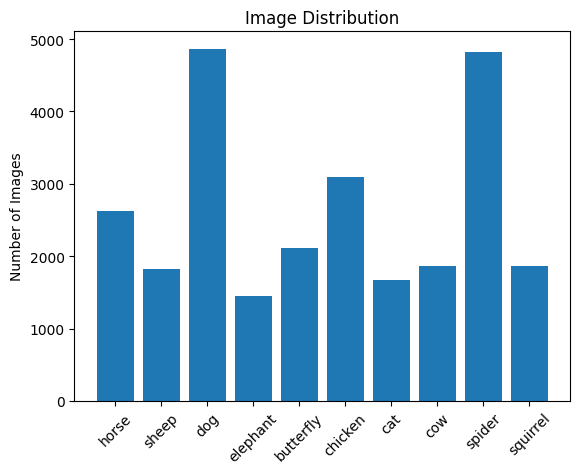

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
image_count = []

for folder in os.listdir(images_path):
  #count number of images in each folder
  folder_path = os.path.join(images_path, folder)
  num_images = len(os.listdir(folder_path))

  image_count.append((folder, num_images))

dist_df = pd.DataFrame(image_count, columns=['Folder', 'Count'])

plt.bar(dist_df['Folder'], dist_df['Count'])
plt.title('Image Distribution')
plt.ylabel('Number of Images')
plt.xticks(rotation=45)

plt.savefig('image_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

#files.download('image_distribution.png')

Look at image dimensions in the dog folder

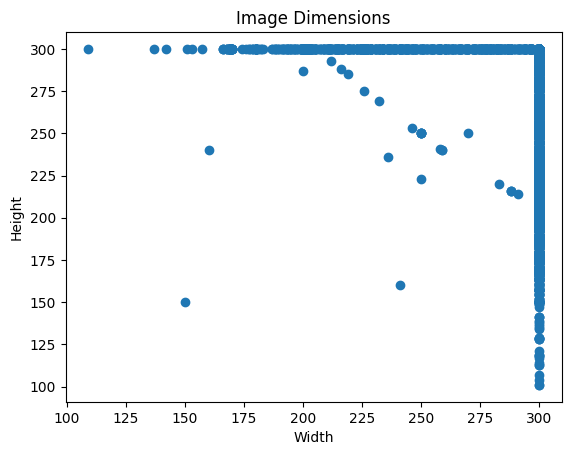

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
folder_path = os.path.join(images_path, 'dog')

image_dimensions = []

for file in os.listdir(folder_path):
    image_path = os.path.join(folder_path, file)

    with Image.open(image_path) as img:
        width, height = img.size

    image_dimensions.append((file, width, height))

dim_df = pd.DataFrame(image_dimensions, columns=['File', 'Width', 'Height'])

plt.scatter(dim_df['Width'], dim_df['Height'])
plt.title('Image Dimensions')
plt.xlabel('Width')
plt.ylabel('Height')

plt.savefig('image_size_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

files.download('image_size_distribution.png')

Check for corrupt images

In [3]:
for folder in os.listdir(images_path):
  folder_path = os.path.join(images_path, folder)

  for file in os.listdir(folder_path):
        image_path = os.path.join(folder_path, file)

        try: #use this because we know there may be errors
            with Image.open(image_path) as img:
                img.verify()
        except Exception:
            print("Corrupted image:", image_path)

Check how many images have different color formats

In [5]:
color_counts = {}

for folder in os.listdir(images_path):
    folder_path = os.path.join(images_path, folder)

    for file in os.listdir(folder_path):
        image_path = os.path.join(folder_path, file)

        with Image.open(image_path) as img:
            mode = img.mode
            color_counts[mode] = color_counts.get(mode, 0) + 1

print(color_counts)


#delete the images that are not RGB
for folder in os.listdir(images_path):
    folder_path = os.path.join(images_path, folder)

    for file in os.listdir(folder_path):
        image_path = os.path.join(folder_path, file)

        with Image.open(image_path) as img:
            if img.mode != "RGB":
                print("Non-RGB:", image_path)
                #os.remove(image_path)

{'RGB': 26128, 'RGBA': 49, 'CMYK': 1, 'L': 1}
Non-RGB: /content/drive/MyDrive/animals10/raw-img/elephant/ea35b80a2df1033ed1584d05fb1d4e9fe777ead218ac104497f5c978a4efb4bb_640.png
Non-RGB: /content/drive/MyDrive/animals10/raw-img/elephant/ea35b80a2df1053ed1584d05fb1d4e9fe777ead218ac104497f5c978a4efb4bb_640.png
Non-RGB: /content/drive/MyDrive/animals10/raw-img/elephant/ea34b10b21f5083ed1584d05fb1d4e9fe777ead218ac104497f5c978a4efb4bb_640.jpg
Non-RGB: /content/drive/MyDrive/animals10/raw-img/elephant/e835b50620f7083ed1584d05fb1d4e9fe777ead218ac104497f5c978a4eebdbd_640.png
Non-RGB: /content/drive/MyDrive/animals10/raw-img/elephant/ea35b80a2df1043ed1584d05fb1d4e9fe777ead218ac104497f5c978a4efb4bb_640.png
Non-RGB: /content/drive/MyDrive/animals10/raw-img/elephant/e83db7072afd013ed1584d05fb1d4e9fe777ead218ac104497f5c978a4eebdbd_640.jpg
Non-RGB: /content/drive/MyDrive/animals10/raw-img/elephant/e835b50620f7093ed1584d05fb1d4e9fe777ead218ac104497f5c978a4eebdbd_640.png
Non-RGB: /content/drive/MyDriv

# Model building / Model choice
